# Tutorial 07: ANN and LSTM for multivariate traffic forecasting

Traffic state is a sequence: flow, occupancy and speed change together, and their order matters. We use the previous hour from one PeMSD4 detector to predict traffic flow one hour ahead. A feed-forward ANN and an LSTM receive exactly the same measurements; the difference is whether the model sees a flattened vector or an ordered sequence.

Along the way, pay attention to three ideas that matter more than the model name:

1. the exact meanings of $N$, $T$ and $D$ in the input shape $(N,T,D)$;
2. chronological splitting and train-only scaling; and
3. comparison with a persistence baseline.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `07 Recurrent neural networks`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [ ]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "07 Recurrent neural networks"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics. PyTorch builds the neural networks used in this lesson.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [ ]:
%pip install numpy pandas matplotlib scikit-learn torch


## Open the notebook

The data file should sit beside this notebook.

In [1]:
from pathlib import Path

if not Path("pems04_single_sensor.csv.gz").exists():
    !git clone -q https://github.com/JinTaoKe/AI-Code.git
    %cd "AI-Code/07 Recurrent neural networks"

In [2]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


## 1. Inspect the sequence

Each row is one five-minute observation from one PeMSD4 loop detector. The three feature columns describe the same traffic stream: flow, occupancy and speed. Using one detector keeps the tensor easy to read before later modules introduce many spatial nodes.

table shape: (12000, 3) = (time steps, traffic variables)
time range: 2018-01-01 00:00:00 to 2018-02-11 15:55:00


,flow,occupancy,speed
time,,,
2018-01-01 00:00:00,81.0,0.0094,69.0
2018-01-01 00:05:00,66.0,0.0080,69.6
2018-01-01 00:10:00,90.0,0.0105,69.0
2018-01-01 00:15:00,117.0,0.0127,68.8
2018-01-01 00:20:00,114.0,0.0125,69.4


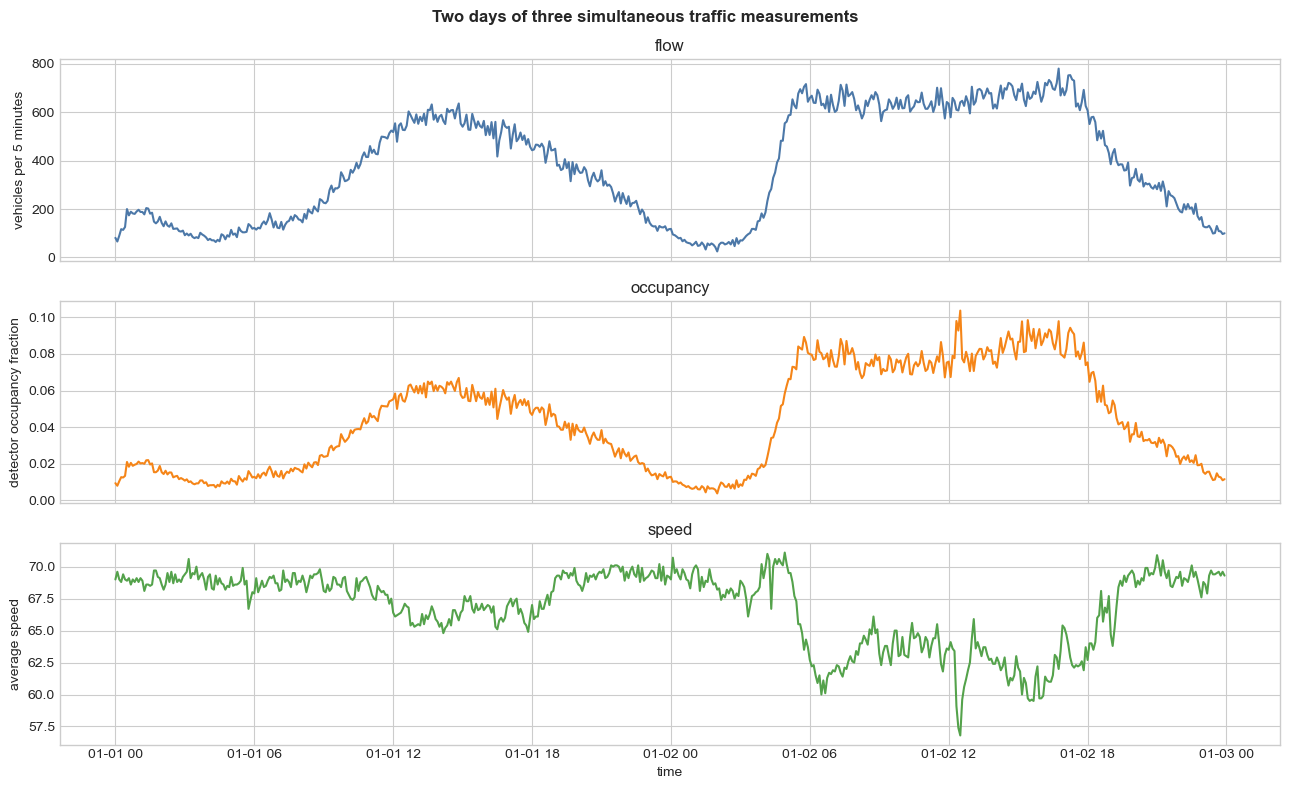

In [3]:
traffic = pd.read_csv(
    "pems04_single_sensor.csv.gz",
    parse_dates=["time"],
).set_index("time")
traffic = traffic.iloc[:12000].copy()

print("table shape:", traffic.shape, "= (time steps, traffic variables)")
print("time range:", traffic.index.min(), "to", traffic.index.max())
display(traffic.head())

two_days = traffic.iloc[: 2 * 24 * 12]
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
plot_settings = [
    ("flow", "vehicles per 5 minutes", "#4C78A8"),
    ("occupancy", "detector occupancy fraction", "#F58518"),
    ("speed", "average speed", "#54A24B"),
]
for ax, (feature, unit, color) in zip(axes, plot_settings):
    ax.plot(two_days.index, two_days[feature], color=color, linewidth=1.5)
    ax.set_ylabel(unit)
    ax.set_title(feature)
axes[-1].set_xlabel("time")
fig.suptitle("Two days of three simultaneous traffic measurements", fontweight="bold")
plt.tight_layout()

## 2. Split first, then scale for neural-network fitting

The first 7,500 steps train the models, the next 2,000 choose the stopping epoch, and the remaining 2,500 estimate performance. Scaling is retained because flow, occupancy, and speed have very different numerical ranges and neural networks train more reliably when their inputs are comparable. The scaler uses training data only. All data previews, MAE/RMSE values, and prediction plots are converted back to the original units.

In [ ]:
train_end = 7500
valid_end = 9500
values = traffic.to_numpy(dtype="float32")
feature_mean = values[:train_end].mean(axis=0)
feature_std = values[:train_end].std(axis=0)
scaled_values = (values - feature_mean) / feature_std
flow_mean = float(feature_mean[0])
flow_std = float(feature_std[0])

scaling_table = pd.DataFrame({
    "feature": traffic.columns,
    "training mean": feature_mean,
    "training standard deviation": feature_std,
})
print("Scaling parameters learned from the training period (shown in original units):")
display(scaling_table.round(3))
print("Chronological split in five-minute time steps:")
print("  train:", train_end, "validation:", valid_end - train_end, "test:", len(values) - valid_end)

## 3. Convert the timeline into supervised windows

We use $T=12$ historical five-minute intervals, so each input covers one hour. At every interval $t$, the feature vector is $[\text{flow}_t,\text{occupancy}_t,\text{speed}_t]$, hence $D=3$. The target is one flow value one hour after the input window ends.

For the complete dataset:

- $N$ = number of sliding-window samples;
- $T=12$ = historical intervals per sample;
- $D=3$ = traffic variables per interval;
- LSTM input $X$ has shape $(N,T,D)$ and target $y$ has shape $(N,1)$;
- ANN input is constructed explicitly as a two-dimensional matrix $(N,T\times D)$ before it enters the model.

The three channels are variables from one detector, not three different stations. The target timestamp determines whether a sample belongs to train, validation or test.

In [ ]:
def make_one_step_windows(array, lookback, forecast_horizon):
    input_windows = []
    flow_targets = []
    target_positions = []

    first_target = lookback + forecast_horizon - 1
    for target_position in range(first_target, len(array)):
        input_end = target_position - forecast_horizon
        input_start = input_end - lookback + 1

        input_windows.append(array[input_start : input_end + 1])
        flow_targets.append(array[target_position, 0])
        target_positions.append(target_position)

    X = np.stack(input_windows).astype("float32")
    y = np.asarray(flow_targets, dtype="float32").reshape(-1, 1)
    target_positions = np.asarray(target_positions)
    return X, y, target_positions


class TrafficANN(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self, x):
        # x is already a two-dimensional ANN design matrix: (N, T × D).
        return self.network(x)


class TrafficLSTM(nn.Module):
    def __init__(self, n_features, hidden_size=48):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        hidden_sequence, _ = self.lstm(x)
        final_hidden_state = hidden_sequence[:, -1, :]
        return self.output(final_hidden_state)

def fit_model(model, train_loader, valid_loader, epochs=8, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"train MAE": [], "valid MAE": []}
    best_state = None
    best_loss = float("inf")
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        train_absolute_error = 0
        train_targets = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            prediction = model(xb)
            loss = loss_fn(prediction, yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(xb)
            train_absolute_error += torch.abs(
                (prediction - yb) * flow_std
            ).sum().item()
            train_targets += yb.numel()

        model.eval()
        valid_loss = 0
        valid_absolute_error = 0
        valid_targets = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                prediction = model(xb)
                valid_loss += loss_fn(prediction, yb).item() * len(xb)
                valid_absolute_error += torch.abs(
                    (prediction - yb) * flow_std
                ).sum().item()
                valid_targets += yb.numel()
        train_loss /= len(train_loader.dataset)
        valid_loss /= len(valid_loader.dataset)
        train_mae = train_absolute_error / train_targets
        valid_mae = valid_absolute_error / valid_targets
        history["train MAE"].append(train_mae)
        history["valid MAE"].append(valid_mae)
        if valid_mae < best_loss:
            best_loss = valid_mae
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"epoch {epoch+1:02d} | "
            f"train MAE {train_mae:.2f} | "
            f"validation MAE {valid_mae:.2f} vehicles/5 min"
        )
    model.load_state_dict(best_state)
    return history

def predict(model, X, batch_size=256):
    model.eval()
    outputs = []
    loader = DataLoader(
        TensorDataset(torch.tensor(X)),
        batch_size=batch_size,
    )
    with torch.no_grad():
        for (xb,) in loader:
            outputs.append(model(xb.to(DEVICE)).cpu().numpy())
    return np.concatenate(outputs)

In [ ]:
LOOKBACK = 12
FORECAST_HORIZON = 12
N_FEATURES = 3

X, y, target_positions = make_one_step_windows(
    scaled_values,
    lookback=LOOKBACK,
    forecast_horizon=FORECAST_HORIZON,
)

train_mask = target_positions < train_end
valid_mask = (target_positions >= train_end) & (target_positions < valid_end)
test_mask = target_positions >= valid_end

X_train = X[train_mask]
y_train = y[train_mask]
X_valid = X[valid_mask]
y_valid = y[valid_mask]
X_test = X[test_mask]
y_test = y[test_mask]

# The LSTM keeps time and feature axes. The ANN receives a conventional
# two-dimensional design matrix prepared before the model call.
X_train_ann = X_train.reshape(len(X_train), LOOKBACK * N_FEATURES)
X_valid_ann = X_valid.reshape(len(X_valid), LOOKBACK * N_FEATURES)
X_test_ann = X_test.reshape(len(X_test), LOOKBACK * N_FEATURES)

print("N =", len(X_train), "training samples")
print("T =", X_train.shape[1], "historical intervals per sample")
print("D =", X_train.shape[2], "features per interval")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_valid:", X_valid.shape, "y_valid:", y_valid.shape)
print("Sequence arrays used by LSTM:")
print("  X_train_lstm:", X_train.shape, "y_train:", y_train.shape)
print("  X_valid_lstm:", X_valid.shape, "y_valid:", y_valid.shape)
print("  X_test_lstm :", X_test.shape, "y_test :", y_test.shape)
print("Flattened design matrices used by ANN:")
print("  X_train_ann:", X_train_ann.shape, "= (N, T × D)")
print("  X_valid_ann:", X_valid_ann.shape)
print("  X_test_ann :", X_test_ann.shape)

first_window_raw = pd.DataFrame(
    X_train[0] * feature_std + feature_mean,
    columns=["flow [vehicles/5 min]", "occupancy [fraction]", "speed"],
)
print("First training input window in original units (12 intervals = one hour):")
display(first_window_raw.round(2))

ann_train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train_ann), torch.tensor(y_train)),
    batch_size=128,
    shuffle=True,
)
ann_valid_loader = DataLoader(
    TensorDataset(torch.tensor(X_valid_ann), torch.tensor(y_valid)),
    batch_size=256,
)
lstm_train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
    batch_size=128,
    shuffle=True,
)
lstm_valid_loader = DataLoader(
    TensorDataset(torch.tensor(X_valid), torch.tensor(y_valid)),
    batch_size=256,
)

## 4. Same information, two feature structures

Both models use the same 36 measurements and predict one future flow value, but we prepare different input arrays before calling them. The ANN receives `X_ann` with shape $(N,36)$, so time position becomes just another feature column. The LSTM receives `X_lstm` with shape $(N,12,3)$ and reads 12 ordered feature vectors, each containing flow, occupancy and speed. Its final hidden state summarizes the ordered hour, and a linear layer maps that summary to one prediction.

This is a fair architecture comparison: the data, target, split and loss are identical. Only the way the model processes the feature structure changes.

In [ ]:
models = {
    "ANN": TrafficANN(
        input_size=LOOKBACK * N_FEATURES,
        hidden_size=64,
    ).to(DEVICE),
    "LSTM": TrafficLSTM(
        n_features=N_FEATURES,
        hidden_size=48,
    ).to(DEVICE),
}

demo_inputs = {
    "ANN": torch.tensor(X_train_ann[:4]).to(DEVICE),
    "LSTM": torch.tensor(X_train[:4]).to(DEVICE),
}
for model_name, model in models.items():
    demo_input = demo_inputs[model_name]
    n_parameters = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )
    with torch.no_grad():
        demo_output = model(demo_input)

    print(f"{model_name}: {n_parameters:,} trainable parameters")
    print("  input shape :", tuple(demo_input.shape))
    print("  output shape:", tuple(demo_output.shape))

## 5. Train both models while watching validation loss

Training loss tells us how well each model fits seen examples. Validation loss tells us whether that fit transfers to the later validation period. For each architecture, the helper restores the epoch with the lowest validation loss; the test period is still untouched.

In [ ]:
histories = {}
model_loaders = {
    "ANN": (ann_train_loader, ann_valid_loader),
    "LSTM": (lstm_train_loader, lstm_valid_loader),
}
for model_name, model in models.items():
    print()
    print(f"Training {model_name}")
    train_loader, valid_loader = model_loaders[model_name]
    torch.manual_seed(42)
    histories[model_name] = fit_model(
        model,
        train_loader,
        valid_loader,
        epochs=18,
        lr=1e-3,
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (model_name, history) in zip(axes, histories.items()):
    epochs = np.arange(1, len(history["train MAE"]) + 1)
    ax.plot(epochs, history["train MAE"], marker="o", label="training")
    ax.plot(epochs, history["valid MAE"], marker="o", label="validation")
    ax.set_title(f"{model_name} learning curve")
    ax.set_xlabel("epoch")
    ax.set_ylabel("MAE [vehicles per 5 minutes]")
    ax.legend()
plt.tight_layout()

## 6. Final comparison after validation tuning

Validation loss fixes the stopping epoch for both learned models. Persistence has no trainable parameters: it predicts that the future flow will equal the last observed flow. Once ANN and LSTM are frozen, all three methods are evaluated on the test period once. The test results are for final comparison, not another round of tuning.

In [ ]:
observed = y_test * flow_std + flow_mean
persistence = X_test[:, -1, 0:1] * flow_std + flow_mean
ann_prediction = predict(models["ANN"], X_test_ann)
ann_prediction = ann_prediction * flow_std + flow_mean
lstm_prediction = predict(models["LSTM"], X_test)
lstm_prediction = lstm_prediction * flow_std + flow_mean

def report(name, pred):
    errors = observed - pred
    return {
        "model": name,
        "MAE": np.abs(errors).mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
    }

results = pd.DataFrame([
    report("Persistence", persistence),
    report("ANN", ann_prediction),
    report("LSTM", lstm_prediction),
])
display(results.round(3))

## 7. Visualize predictions and errors

The table compresses the whole test period into two numbers. The time plot below shows two test days, so we can see whether a method follows peaks and troughs. The bar chart shows the same final test MAE values side by side; lower bars are better.

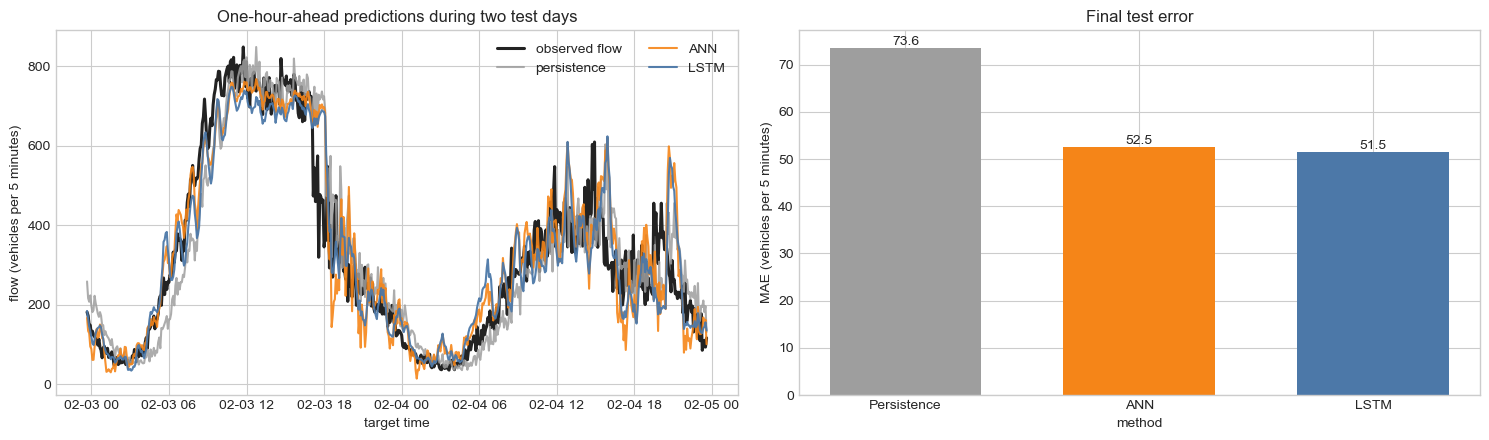

In [10]:
window = slice(0, 2 * 24 * 12)
test_times = traffic.index[target_positions[test_mask]]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(
    test_times[window],
    observed[window, 0],
    color="#222222",
    linewidth=2.2,
    label="observed flow",
)
axes[0].plot(
    test_times[window],
    persistence[window, 0],
    color="#9E9E9E",
    alpha=0.85,
    label="persistence",
)
axes[0].plot(
    test_times[window],
    ann_prediction[window, 0],
    color="#F58518",
    alpha=0.9,
    label="ANN",
)
axes[0].plot(
    test_times[window],
    lstm_prediction[window, 0],
    color="#4C78A8",
    alpha=0.95,
    label="LSTM",
)
axes[0].set_title("One-hour-ahead predictions during two test days")
axes[0].set_xlabel("target time")
axes[0].set_ylabel("flow (vehicles per 5 minutes)")
axes[0].legend(ncol=2)

bar_colors = ["#9E9E9E", "#F58518", "#4C78A8"]
axes[1].bar(
    results["model"],
    results["MAE"],
    color=bar_colors,
    width=0.65,
)
axes[1].set_title("Final test error")
axes[1].set_xlabel("method")
axes[1].set_ylabel("MAE (vehicles per 5 minutes)")
for index, value in enumerate(results["MAE"]):
    axes[1].text(index, value, f"{value:.1f}", ha="center", va="bottom")
plt.tight_layout()

## 8. Extension: how many future intervals should one LSTM predict?

The earlier experiment predicts **one value at a fixed horizon**: after reading $T=12$ historical intervals, the model estimates flow one hour later. Multi-step forecasting asks a different question: after reading the same history, can one model predict the **continuous trajectory immediately after the input window**?

For sample $n$:

- input $X_n$ contains the previous $T=12$ intervals of flow, occupancy and speed, so $X_n$ has shape $(T,3)$;
- target $Y_n=[y_{t+1},y_{t+2},\ldots,y_{t+H}]$ contains the next $H$ flow values, so $Y_n$ has shape $(H,1)$;
- a batch therefore has `X.shape = (N, T, 3)` and `Y.shape = (N, H, 1)`;
- the LSTM reads the historical sequence, and its final hidden state is mapped directly to $H$ output values.

We train separate models for $H\in\{1,3,5,12\}$. Because one interval is five minutes, these models output the next 5, 15, 25 and 60 minutes respectively. The main score is the average error over every sample and every requested future interval:

$$
\operatorname{MAE}_{\mathrm{average}}
=\frac{1}{NH}\sum_{n=1}^{N}\sum_{h=1}^{H}
\left|y_{n,h}-\hat y_{n,h}\right|.
$$

This average answers: "Across the entire predicted trajectory, how far is a typical predicted flow from the observation?" We also inspect the 12-step model separately to see how error changes from 5 minutes ahead to 60 minutes ahead.

In [ ]:
def make_multistep_windows(array, lookback, output_steps):
    input_windows = []
    future_flow_sequences = []
    first_target_positions = []
    last_target_positions = []

    last_input_start = len(array) - lookback - output_steps
    for input_start in range(last_input_start + 1):
        input_end = input_start + lookback
        output_end = input_end + output_steps

        input_windows.append(array[input_start:input_end])
        future_flow_sequences.append(array[input_end:output_end, 0:1])
        first_target_positions.append(input_end)
        last_target_positions.append(output_end - 1)

    X_sequence = np.stack(input_windows).astype("float32")
    Y_sequence = np.stack(future_flow_sequences).astype("float32")
    return (
        X_sequence,
        Y_sequence,
        np.asarray(first_target_positions),
        np.asarray(last_target_positions),
    )


class MultiStepLSTM(nn.Module):
    def __init__(self, n_features, hidden_size, output_steps):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.output = nn.Linear(hidden_size, output_steps)

    def forward(self, x):
        hidden_sequence, _ = self.lstm(x)
        final_hidden_state = hidden_sequence[:, -1, :]
        future_flow = self.output(final_hidden_state)
        return future_flow.unsqueeze(-1)


OUTPUT_STEP_OPTIONS = [1, 3, 5, 12]
multi_step_records = []
multi_step_test_details = {}

for output_steps in OUTPUT_STEP_OPTIONS:
    print()
    print(
        f"Predicting H={output_steps} future intervals "
        f"({output_steps * 5} minutes)"
    )

    X_multi, Y_multi, first_targets, last_targets = make_multistep_windows(
        scaled_values,
        lookback=LOOKBACK,
        output_steps=output_steps,
    )

    # Every target in a sample must stay inside one chronological split.
    train_multi = last_targets < train_end
    valid_multi = (
        (first_targets >= train_end)
        & (last_targets < valid_end)
    )
    test_multi = first_targets >= valid_end

    X_train_multi = X_multi[train_multi]
    Y_train_multi = Y_multi[train_multi]
    X_valid_multi = X_multi[valid_multi]
    Y_valid_multi = Y_multi[valid_multi]
    X_test_multi = X_multi[test_multi]
    Y_test_multi = Y_multi[test_multi]

    print("  X_train:", X_train_multi.shape, "= (N, T, D)")
    print("  Y_train:", Y_train_multi.shape, "= (N, H, 1)")

    train_multi_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_train_multi),
            torch.tensor(Y_train_multi),
        ),
        batch_size=128,
        shuffle=True,
    )
    valid_multi_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_valid_multi),
            torch.tensor(Y_valid_multi),
        ),
        batch_size=256,
    )

    torch.manual_seed(42)
    multi_step_model = MultiStepLSTM(
        n_features=N_FEATURES,
        hidden_size=48,
        output_steps=output_steps,
    ).to(DEVICE)
    fit_model(
        multi_step_model,
        train_multi_loader,
        valid_multi_loader,
        epochs=8,
        lr=1e-3,
    )

    prediction_scaled = predict(multi_step_model, X_test_multi)
    prediction = prediction_scaled * flow_std + flow_mean
    observation = Y_test_multi * flow_std + flow_mean

    persistence_scaled = np.repeat(
        X_test_multi[:, -1:, 0:1],
        output_steps,
        axis=1,
    )
    persistence_prediction = persistence_scaled * flow_std + flow_mean

    lstm_error = np.abs(prediction - observation)
    persistence_error = np.abs(persistence_prediction - observation)
    multi_step_records.append({
        "output steps H": output_steps,
        "output duration [min]": output_steps * 5,
        "test samples": len(X_test_multi),
        "LSTM average MAE": lstm_error.mean(),
        "persistence average MAE": persistence_error.mean(),
        "LSTM final-step MAE": lstm_error[:, -1].mean(),
    })
    multi_step_test_details[output_steps] = {
        "observation": observation,
        "prediction": prediction,
        "persistence": persistence_prediction,
        "MAE by horizon": lstm_error.mean(axis=(0, 2)),
        "persistence MAE by horizon": persistence_error.mean(axis=(0, 2)),
    }


multi_step_results = pd.DataFrame(multi_step_records)
print("\nAverage test error across all requested output intervals:")
print(multi_step_results.round(2).to_string(index=False))

details_12 = multi_step_test_details[12]
forecast_minutes = np.arange(5, 65, 5)
peak_sample = int(details_12["observation"].mean(axis=(1, 2)).argmax())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(
    multi_step_results["output steps H"],
    multi_step_results["LSTM average MAE"],
    marker="o",
    linewidth=2,
    color="#4C78A8",
    label="LSTM",
)
axes[0].plot(
    multi_step_results["output steps H"],
    multi_step_results["persistence average MAE"],
    marker="o",
    linewidth=2,
    color="#9E9E9E",
    label="persistence",
)
axes[0].set_title("Average error for different output lengths")
axes[0].set_xlabel("number of future intervals H")
axes[0].set_ylabel("average test MAE [vehicles/5 min]")
axes[0].set_xticks(OUTPUT_STEP_OPTIONS)
axes[0].legend()

axes[1].plot(
    forecast_minutes,
    details_12["MAE by horizon"],
    marker="o",
    linewidth=2,
    color="#4C78A8",
    label="LSTM",
)
axes[1].plot(
    forecast_minutes,
    details_12["persistence MAE by horizon"],
    marker="o",
    linewidth=2,
    color="#9E9E9E",
    label="persistence",
)
axes[1].set_title("12-step model: error at each horizon")
axes[1].set_xlabel("minutes after the input window")
axes[1].set_ylabel("test MAE [vehicles/5 min]")
axes[1].legend()

axes[2].plot(
    forecast_minutes,
    details_12["observation"][peak_sample, :, 0],
    marker="o",
    linewidth=2.2,
    color="#222222",
    label="observed",
)
axes[2].plot(
    forecast_minutes,
    details_12["prediction"][peak_sample, :, 0],
    marker="o",
    color="#4C78A8",
    label="LSTM",
)
axes[2].plot(
    forecast_minutes,
    details_12["persistence"][peak_sample, :, 0],
    linestyle="--",
    color="#9E9E9E",
    label="persistence",
)
axes[2].set_title("Example one-hour trajectory")
axes[2].set_xlabel("minutes after the input window")
axes[2].set_ylabel("flow [vehicles/5 min]")
axes[2].legend()

plt.tight_layout()
plt.show()


## What to remember

- $N$ counts samples, $T$ counts historical intervals, and $D$ counts variables observed at each interval.
- Here, $D=3$ means flow, occupancy and speed from one detector; it does not mean three stations.
- ANN and LSTM can use the same measurements, but ANN flattens time while LSTM preserves its order.
- Split chronologically, fit scaling on training data only, tune with validation data, then compare all frozen models once on test data.
- Fixed-horizon single-step forecasting predicts one selected future time; multi-step forecasting predicts the continuous next trajectory with target shape $(N,H,1)$.
- For multi-step results, report both the average error across all $H$ outputs and the error at each forecast horizon; always compare with a simple baseline.